# Testing with pytest

An automated **test** is code that calls your code with known inputs and checks the result. Tests find bugs early, document the expected behaviour, and make changes safe: if all tests pass after a change, the old behaviour still works. **pytest** is the standard test framework for Python.

**After this lesson you can:**

1. Write and run tests with plain `assert` statements.
2. Use fixtures, parametrisation and `pytest.raises`.
3. Isolate code from files, time and networks with `tmp_path` and `monkeypatch`.
4. Read a test report and explain the test pyramid.

## 1. A Small Package to Test

The cell creates a project in a temporary folder:

```
shop/                       tests/
└── pricing.py              ├── test_pricing.py
                            └── conftest.py     # shared fixtures
```

In [1]:
import subprocess
import sys
import tempfile
import textwrap
import xml.etree.ElementTree as ET
from pathlib import Path

work = Path(tempfile.mkdtemp())
(work / "shop").mkdir()
(work / "tests").mkdir()
(work / "shop" / "__init__.py").write_text("")
(work / "shop" / "pricing.py").write_text(textwrap.dedent("""
    import json
    import urllib.request
    from pathlib import Path

    VAT = 0.20

    def gross(net: float, discount: float = 0.0) -> float:
        if net < 0:
            raise ValueError("net price must not be negative")
        if not 0 <= discount < 1:
            raise ValueError("discount must be in [0, 1)")
        return round(net * (1 + VAT) * (1 - discount), 2)

    def load_prices(path: Path) -> dict[str, float]:
        return {k: float(v) for k, v in json.loads(path.read_text()).items()}

    def fetch_exchange_rate(currency: str) -> float:
        # Calls an external service. Tests must not depend on the network.
        with urllib.request.urlopen(f"https://example.com/rates/{currency}") as r:
            return float(json.load(r)["rate"])

    def price_in(currency: str, net: float) -> float:
        return round(gross(net) * fetch_exchange_rate(currency), 2)
"""))
print((work / "shop" / "pricing.py").read_text())


import json
import urllib.request
from pathlib import Path

VAT = 0.20

def gross(net: float, discount: float = 0.0) -> float:
    if net < 0:
        raise ValueError("net price must not be negative")
    if not 0 <= discount < 1:
        raise ValueError("discount must be in [0, 1)")
    return round(net * (1 + VAT) * (1 - discount), 2)

def load_prices(path: Path) -> dict[str, float]:
    return {k: float(v) for k, v in json.loads(path.read_text()).items()}

def fetch_exchange_rate(currency: str) -> float:
    # Calls an external service. Tests must not depend on the network.
    with urllib.request.urlopen(f"https://example.com/rates/{currency}") as r:
        return float(json.load(r)["rate"])

def price_in(currency: str, net: float) -> float:
    return round(gross(net) * fetch_exchange_rate(currency), 2)



## 2. Write the Tests

pytest finds files named `test_*.py` and functions named `test_*`. A test passes if it finishes without an exception. pytest shows the values in a failed `assert`, so you do not need special assertion methods.

| Feature | Use |
| :--- | :--- |
| `@pytest.mark.parametrize` | run one test with many inputs |
| `pytest.raises(Error)` | check that code raises an exception |
| `pytest.approx` | compare floats with a tolerance |
| **fixture** | reusable set-up; requested by parameter name |
| `tmp_path` | a built-in fixture: a new temporary folder for each test |
| `monkeypatch` | replace a function or environment variable during a test |

In [2]:
(work / "tests" / "conftest.py").write_text(textwrap.dedent("""
    import json
    import pytest

    @pytest.fixture
    def price_file(tmp_path):
        # A JSON price file in a temporary folder.
        path = tmp_path / "prices.json"
        path.write_text(json.dumps({"pen": "1.50", "book": 12}))
        return path
"""))
(work / "tests" / "test_pricing.py").write_text(textwrap.dedent("""
    import pytest
    from shop import pricing

    def test_gross_adds_vat():
        assert pricing.gross(100) == 120.0

    @pytest.mark.parametrize("net, discount, expected", [
        (100, 0.0, 120.0),
        (100, 0.5, 60.0),
        (0, 0.0, 0.0),
        (19.99, 0.1, 21.59),
    ])
    def test_gross_table(net, discount, expected):
        assert pricing.gross(net, discount) == pytest.approx(expected)

    @pytest.mark.parametrize("net, discount", [(-1, 0), (10, 1.0), (10, -0.1)])
    def test_gross_rejects_invalid_input(net, discount):
        with pytest.raises(ValueError):
            pricing.gross(net, discount)

    def test_load_prices_converts_to_float(price_file):
        assert pricing.load_prices(price_file) == {"pen": 1.5, "book": 12.0}

    def test_price_in_uses_rate_without_network(monkeypatch):
        monkeypatch.setattr(pricing, "fetch_exchange_rate", lambda currency: 35.0)
        assert pricing.price_in("TRY", 10) == 420.0

    def test_known_bug_example():
        # This test fails on purpose, to show how pytest reports a failure.
        assert pricing.gross(10, 0.25) == 9.5
"""))
print("tests written:", [p.name for p in (work / "tests").iterdir()])

tests written: ['test_pricing.py', 'conftest.py']


## 3. Run pytest

The cell runs pytest in the project folder and writes a JUnit XML report. CI systems read this format.

In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--junitxml=report.xml",
                    "--durations=3", "tests"], cwd=work, capture_output=True, text=True)
print(r.stdout.replace(str(work) + "/", "")[-2500:])
print("exit code:", r.returncode, "(0 = all passed, 1 = some tests failed)")

..........F                                                              [100%]
=================================== FAILURES ===================================
____________________________ test_known_bug_example ____________________________

    def test_known_bug_example():
        # This test fails on purpose, to show how pytest reports a failure.
>       assert pricing.gross(10, 0.25) == 9.5
E       assert 9.0 == 9.5
E        +  where 9.0 = <function gross at 0x7ff717a9aca0>(10, 0.25)
E        +    where <function gross at 0x7ff717a9aca0> = pricing.gross

tests/test_pricing.py:31: AssertionError
============================= slowest 3 durations ==============================

(3 durations < 0.005s hidden.  Use -vv to show these durations.)
=========================== short test summary info ============================
FAILED tests/test_pricing.py::test_known_bug_example - assert 9.0 == 9.5
1 failed, 10 passed in 0.55s

exit code: 1 (0 = all passed, 1 = some tests failed)


pytest shows the failed test with the actual and the expected value: `gross(10, 0.25)` is 9.0, not 9.5 (the expected value in the test was wrong, not the code). In a real project you fix either the code or the test, then run pytest again.

## 4. Visualise the Test Report

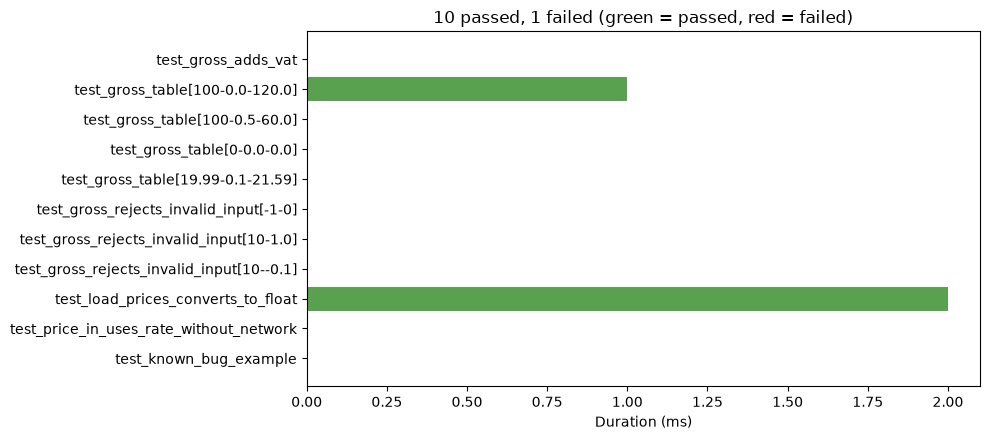

In [4]:
import matplotlib.pyplot as plt

root = ET.parse(work / "report.xml").getroot()
cases = []
for tc in root.iter("testcase"):
    status = "failed" if tc.find("failure") is not None else "passed"
    cases.append((tc.get("name"), float(tc.get("time")) * 1000, status))

fig, ax = plt.subplots(figsize=(10, 4.5))
names = [c[0] for c in cases]
ax.barh(names, [c[1] for c in cases], color=["#E15759" if c[2] == "failed" else "#59A14F" for c in cases])
ax.set(title=f"{sum(c[2] == 'passed' for c in cases)} passed, {sum(c[2] == 'failed' for c in cases)} failed "
             f"(green = passed, red = failed)", xlabel="Duration (ms)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Every test takes milliseconds, because no test touches the network or a real database. Fast tests run on every change.

## 5. The Test Pyramid

| Level | Tests | Speed | How many |
| :--- | :--- | :--- | :--- |
| **Unit tests** | one function or class, with fakes for I/O | milliseconds | many |
| **Integration tests** | several parts together: code + database, code + API | seconds | some |
| **End-to-end tests** | the whole system, as a user would use it | minutes | few |

For data and ML code, add **data tests** (schema, value ranges, null rates; M10 and M11) and **model tests** (a minimum accuracy on a fixed test set; M34).

*Insight: Write tests that check behaviour, not implementation details, and keep external services (network, time, randomness) out of unit tests with fixtures and `monkeypatch`. A test suite that runs in seconds gets run; a slow one gets skipped.*

## Real-World Use Case or Analogy

Tests are like the **checklist of a car inspection**: brakes, lights, emissions. After every repair, the mechanic runs the same checklist. If one item fails, the car does not go back on the road. Nobody trusts a repair that "probably" works.

In companies, every pull request runs the test suite in CI (M34). A red test blocks the merge. Teams that practise **test-driven development (TDD)** write the failing test first, then the code that makes it pass.